# Time dynamics of sliding-window AR embeddings

This notebook simulates a stationary AR($p$) process with automatically generated coefficients and either

$$
Z_t\sim\mathcal N(0,1)
$$

or

$$
Z_t\sim\mathcal U[-1,1].
$$

It first displays the time series, then the 2D and 3D forward sliding-window embeddings, and finally an animation of the ordered 2D trajectory. In the animation, each new embedded point is added in temporal order and immediately connected to its predecessor.

## 1. Load the shared implementation

In [ ]:
from pathlib import Path
import importlib.util
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

_search_directories = [
    Path.cwd(),
    Path.cwd() / "Code",
    Path.cwd() / "Code" / "Code_AR_processes",
    Path.cwd() / "Code_AR_processes",
    Path.cwd().parent,
    Path.cwd().parent / "Code",
    Path.cwd().parent / "Code_AR_processes",
]
FUNCTIONS_PATH = next(
    (directory / "00_FUNCTIONS.py"
     for directory in _search_directories
     if (directory / "00_FUNCTIONS.py").exists()),
    None,
)
if FUNCTIONS_PATH is None:
    raise FileNotFoundError(
        "Could not find 00_FUNCTIONS.py. Keep it beside the notebook or run "
        "from the repository root, Code/, or Code/Code_AR_processes/."
    )

_spec = importlib.util.spec_from_file_location("ar_scale_functions", FUNCTIONS_PATH)
functions = importlib.util.module_from_spec(_spec)
sys.modules[_spec.name] = functions
_spec.loader.exec_module(functions)
globals().update({name: getattr(functions, name) for name in functions.__all__})

plt.style.use("seaborn-v0_8-whitegrid")
print(f"Loaded shared AR implementation from {FUNCTIONS_PATH}")

## 2. Controls

Choose the AR order and innovation distribution here. The coefficient rule uses partial autocorrelations

$$
\kappa_j=0.75(-0.5)^{j-1},
$$

which guarantees stationary coefficients after the Levinson recursion.

In [5]:
# ========================= USER CONTROLS =========================
p = 1
innovation_distribution = "gaussian"  # choose "gaussian" or "uniform"
n_observations = 250
burn_in = 500
seed = 20260708
animation_interval_ms = 40
# ================================================================

if p < 1:
    raise ValueError("p must be positive.")
if n_observations < 3:
    raise ValueError("At least three observations are required for the 3D embedding.")
if innovation_distribution.lower() not in {"gaussian", "uniform"}:
    raise ValueError("Choose 'gaussian' or 'uniform'.")

## 3. Simulate the AR process

In [6]:
phi = automatic_ar_coefficients(p)
rng = np.random.default_rng(seed)
x = simulate_ar_with_distribution(
    phi=phi,
    n=n_observations,
    burn_in=burn_in,
    innovation_distribution=innovation_distribution,
    rng=rng,
)

embedding_2d = aligned_windows(x, 2).copy()
embedding_3d = aligned_windows(x, 3).copy()

print(f"AR({p}) coefficients: {np.round(phi, 6)}")
print(f"Companion spectral radius: {companion_radius(phi):.6f}")
print(f"Innovations: {innovation_distribution.lower()}")
print(f"Observations: {len(x)}")

AR(1) coefficients: [0.75]
Companion spectral radius: 0.750000
Innovations: gaussian
Observations: 250


## 4. Time series

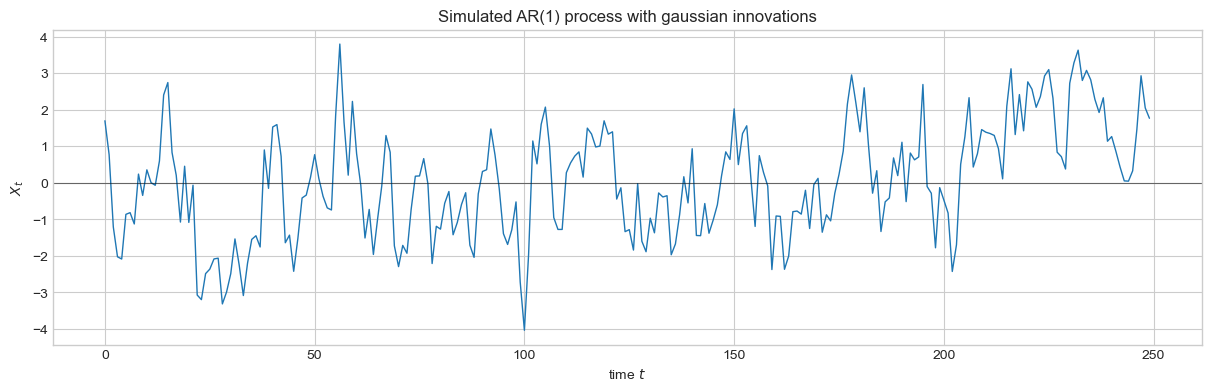

In [7]:
fig, axis = plt.subplots(figsize=(12, 3.8), constrained_layout=True)
axis.plot(np.arange(len(x)), x, color="tab:blue", linewidth=1.0)
axis.axhline(0.0, color="black", linewidth=0.8, alpha=0.5)
axis.set(
    title=f"Simulated AR({p}) process with {innovation_distribution.lower()} innovations",
    xlabel="time $t$",
    ylabel="$X_t$",
)
plt.show()

## 5. Static 2D and 3D sliding-window embeddings

The embeddings are

$$
P_t^{(2)}=(X_t,X_{t+1}),
$$

and

$$
P_t^{(3)}=(X_t,X_{t+1},X_{t+2}).
$$

Colour indicates temporal order. The faint lines connect consecutive embedded states.

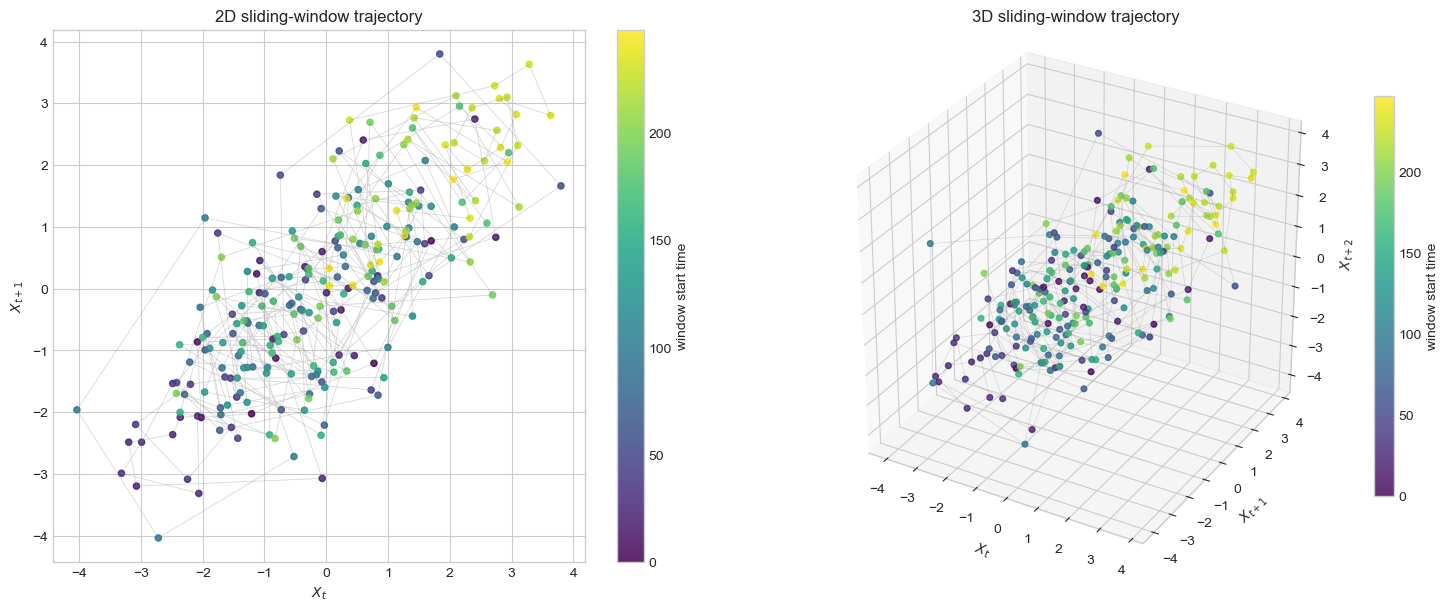

In [9]:
fig = plt.figure(figsize=(15, 6), constrained_layout=True)
axis_2d = fig.add_subplot(1, 2, 1)
axis_3d = fig.add_subplot(1, 2, 2, projection="3d")

colour_2d = np.arange(len(embedding_2d))
axis_2d.plot(
    embedding_2d[:, 0], embedding_2d[:, 1],
    color="tab:gray", linewidth=0.55, alpha=0.32,
)
scatter_2d = axis_2d.scatter(
    embedding_2d[:, 0], embedding_2d[:, 1],
    c=colour_2d, cmap="viridis", s=20, alpha=0.85,
)
axis_2d.set_aspect("equal", adjustable="box")
axis_2d.set(
    title="2D sliding-window trajectory",
    xlabel="$X_t$",
    ylabel="$X_{t+1}$",
)
fig.colorbar(scatter_2d, ax=axis_2d, label="window start time")

colour_3d = np.arange(len(embedding_3d))
axis_3d.plot(
    embedding_3d[:, 0], embedding_3d[:, 1], embedding_3d[:, 2],
    color="tab:gray", linewidth=0.5, alpha=0.28,
)
scatter_3d = axis_3d.scatter(
    embedding_3d[:, 0], embedding_3d[:, 1], embedding_3d[:, 2],
    c=colour_3d, cmap="viridis", s=17, alpha=0.82,
)
axis_3d.set(
    title="3D sliding-window trajectory",
    xlabel="$X_t$",
    ylabel="$X_{t+1}$",
    zlabel="$X_{t+2}$",
)
axis_3d.set_box_aspect((1, 1, 1))
fig.colorbar(scatter_3d, ax=axis_3d, label="window start time", shrink=0.75)

plt.show()

## 6. Animated 2D trajectory

The red point is the current embedded state. Previously visited states and all consecutive connecting segments remain visible. The abstract consecutive-point graph is always a path; the purpose of this animation is to inspect its Euclidean trajectory and direction of motion.

## Interpretation guide

For AR(1), the 2D cloud follows the noisy regression relation

$$
X_{t+1}=\phi X_t+Z_{t+1}.
$$

Positive $\phi$ tends to elongate the cloud along the positive diagonal; negative $\phi$ produces alternating or zigzag motion. AR(2) processes with complex companion eigenvalues can produce visibly rotational trajectories. A stationary linear process with continuous innovations generally fills an ellipsoidal region rather than a genuine topological loop.